In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Library berhasil di-import!")

Library berhasil di-import!


In [ ]:
from pathlib import Path

local_data_candidates = [
    Path("data/data_pelanggan_clean.csv"),
    Path("../data/data_pelanggan_clean.csv"),
    Path("umkm_customer_segmentation-main/data/data_pelanggan_clean.csv"),
    Path("umkm_customer_segmentation-main/umkm_customer_segmentation-main/data/data_pelanggan_clean.csv"),
]
data_path = next((path for path in local_data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("data_pelanggan_clean.csv tidak ditemukan di proyek lokal.")

df = pd.read_csv(data_path)

print("Dataset lokal berhasil dibaca:", data_path)
print("Ukuran dataset:", df.shape)

display(df.head())


In [3]:
print("Informasi Dataset:")
df.info()

print("\nMissing Value:")
display(df.isnull().sum())

print("\nJumlah Duplikat:")
print(df.duplicated().sum())

print("\nStatistik Deskriptif:")
display(df.describe().T)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_pelanggan                   10000 non-null  object 
 1   tanggal_daftar                 10000 non-null  object 
 2   umur                           9745 non-null   float64
 3   kecamatan                      10000 non-null  object 
 4   channel_utama                  10000 non-null  object 
 5   metode_bayar                   10000 non-null  object 
 6   kategori_favorit               10000 non-null  object 
 7   jumlah_transaksi_6bln          10000 non-null  int64  
 8   total_belanja_rp               10000 non-null  int64  
 9   hari_sejak_transaksi_terakhir  10000 non-null  int64  
 10  persen_pakai_promo             10000 non-null  int64  
 11  rating_rata                    9200 non-null   float64
dtypes: float64(2), int64(4), obj

,0
id_pelanggan,0
tanggal_daftar,0
umur,255
kecamatan,0
channel_utama,0
metode_bayar,0
kategori_favorit,0
jumlah_transaksi_6bln,0
total_belanja_rp,0
hari_sejak_transaksi_terakhir,0



Jumlah Duplikat:
0

Statistik Deskriptif:


,count,mean,std,min,25%,50%,75%,max
umur,9745.0,29.021755,8.649662,1.0,23.0,28.0,34.0,99.0
jumlah_transaksi_6bln,10000.0,12.535000,11.643029,1.0,3.0,8.0,20.0,56.0
total_belanja_rp,10000.0,693710.740000,648750.915942,11900.0,152200.0,425050.0,1145325.0,3424200.0
hari_sejak_transaksi_terakhir,10000.0,41.760000,49.352274,0.0,6.0,15.0,75.0,225.0
persen_pakai_promo,10000.0,38.480800,28.020581,0.0,16.0,28.0,65.0,100.0
rating_rata,9200.0,4.153728,0.524695,2.0,3.8,4.2,4.5,5.0


In [4]:

# 1. Menentukan kolom yang tidak digunakan untuk clustering
kolom_dihapus = [
    "id_pelanggan",
    "tanggal_daftar"
]

# 2. Memisahkan fitur yang akan digunakan
X = df.drop(columns=kolom_dihapus, errors="ignore")

# 3. Memisahkan fitur numerik dan kategorikal
fitur_numerik = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

fitur_kategorikal = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 4. Menampilkan hasil
print("Jumlah fitur:", X.shape[1])

print("\nFitur numerik:")
print(fitur_numerik)

print("\nFitur kategorikal:")
print(fitur_kategorikal)

print("\nUkuran data fitur:", X.shape)


Jumlah fitur: 10

Fitur numerik:
['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata']

Fitur kategorikal:
['kecamatan', 'channel_utama', 'metode_bayar', 'kategori_favorit']

Ukuran data fitur: (10000, 10)


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Pipeline untuk fitur numerik
pipeline_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline untuk fitur kategorikal
pipeline_kategorikal = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing numerik dan kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", pipeline_numerik, fitur_numerik),
        ("kategorikal", pipeline_kategorikal, fitur_kategorikal)
    ]
)

# Melakukan preprocessing
X_processed = preprocessor.fit_transform(X)

print("Preprocessing berhasil!")
print("Ukuran data sebelum preprocessing:", X.shape)
print("Ukuran data setelah preprocessing:", X_processed.shape)
print("Jumlah fitur numerik:", len(fitur_numerik))
print("Jumlah fitur kategorikal:", len(fitur_kategorikal))


Preprocessing berhasil!
Ukuran data sebelum preprocessing: (10000, 10)
Ukuran data setelah preprocessing: (10000, 28)
Jumlah fitur numerik: 6
Jumlah fitur kategorikal: 4


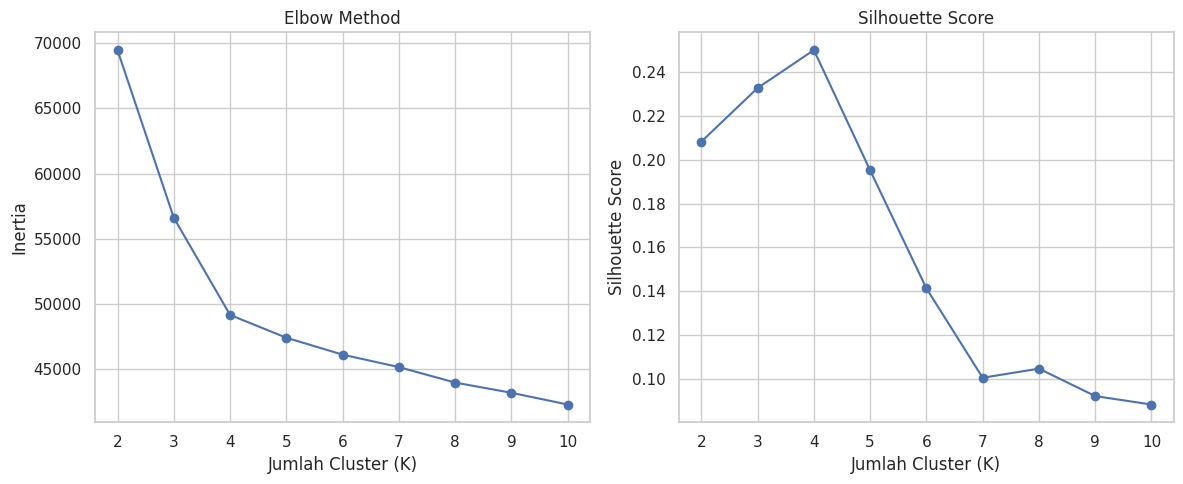

K = 2 | Silhouette Score = 0.2082
K = 3 | Silhouette Score = 0.2326
K = 4 | Silhouette Score = 0.2499
K = 5 | Silhouette Score = 0.1951
K = 6 | Silhouette Score = 0.1414
K = 7 | Silhouette Score = 0.1007
K = 8 | Silhouette Score = 0.1048
K = 9 | Silhouette Score = 0.0923
K = 10 | Silhouette Score = 0.0885


In [6]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Menyiapkan daftar jumlah cluster
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

# Menguji K-Means untuk K = 2 sampai 10
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_processed)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(
            X_processed,
            labels,
            sample_size=3000,
            random_state=42
        )
    )

# Visualisasi Elbow Method
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)

# Visualisasi Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)

plt.tight_layout()
plt.show()

# Menampilkan skor
for k, score in zip(k_values, silhouette_values):
    print(f"K = {k} | Silhouette Score = {score:.4f}")


In [ ]:
# Membuat model K-Means final
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Melatih model dan memberikan label cluster
cluster_labels = kmeans_final.fit_predict(X_processed)

# Menyusun ulang label agar sesuai dengan nama segmen hasil percobaan final
profil_awal = df.assign(cluster=cluster_labels).groupby("cluster")[fitur_numerik].median()
cluster_tidak_aktif = profil_awal["hari_sejak_transaksi_terakhir"].idxmax()
cluster_tersisa = [cluster for cluster in profil_awal.index if cluster != cluster_tidak_aktif]
cluster_promo = profil_awal.loc[cluster_tersisa, "persen_pakai_promo"].idxmax()
cluster_tersisa.remove(cluster_promo)
cluster_belanja_tinggi = profil_awal.loc[cluster_tersisa, "jumlah_transaksi_6bln"].idxmin()
cluster_loyal = next(
    cluster for cluster in cluster_tersisa if cluster != cluster_belanja_tinggi
)
urutan_cluster = [
    cluster_loyal,
    cluster_tidak_aktif,
    cluster_promo,
    cluster_belanja_tinggi,
]
pemetaan_cluster = {
    cluster_asal: cluster_baru
    for cluster_baru, cluster_asal in enumerate(urutan_cluster)
}
kmeans_final.cluster_centers_ = kmeans_final.cluster_centers_[urutan_cluster]
kmeans_final.labels_ = np.array(
    [pemetaan_cluster[label] for label in cluster_labels],
    dtype=int
)
cluster_labels = kmeans_final.labels_.copy()

# Menambahkan hasil cluster ke data
df_hasil = df.copy()
df_hasil["cluster"] = cluster_labels

# Melihat jumlah pelanggan setiap cluster
jumlah_cluster = df_hasil["cluster"].value_counts().sort_index()

print("Jumlah pelanggan setiap cluster:")
print(jumlah_cluster)

print()
print("Persentase pelanggan setiap cluster:")
print((jumlah_cluster / len(df_hasil) * 100).round(2))

print()
print("Contoh hasil segmentasi:")
display(df_hasil.head())


In [ ]:
# Menghitung median karakteristik numerik setiap cluster
profil_cluster = df_hasil.groupby("cluster")[fitur_numerik].median()

print("Profil karakteristik setiap cluster:")
display(profil_cluster)

# Menampilkan jumlah pelanggan per cluster
print("\nJumlah pelanggan:")
display(df_hasil.groupby("cluster").size().to_frame("jumlah_pelanggan"))

In [ ]:

# Membuat pemetaan nama cluster
nama_cluster = {
    0: "Pelanggan Loyal dan Aktif",
    1: "Pelanggan Tidak Aktif",
    2: "Pelanggan Sensitif terhadap Promo",
    3: "Pelanggan Bernilai Belanja Tinggi"
}

# Menambahkan nama segmen
df_hasil["segmen"] = df_hasil["cluster"].map(nama_cluster)

# Menampilkan hasil segmentasi
display(
    df_hasil[
        ["id_pelanggan", "cluster", "segmen"]
    ].head(10)
)

# Ringkasan jumlah setiap segmen
display(
    df_hasil.groupby(["cluster", "segmen"])
    .size()
    .reset_index(name="jumlah_pelanggan")
)


In [ ]:

import joblib
import os

# Membuat folder penyimpanan model
os.makedirs("model", exist_ok=True)

# Menyimpan model K-Means
joblib.dump(kmeans_final, "model/kmeans_model.pkl")

# Menyimpan preprocessing
joblib.dump(preprocessor, "model/preprocessor.pkl")

# Menyimpan hasil segmentasi
df_hasil.to_csv(
    "model/hasil_segmentasi_pelanggan.csv",
    index=False
)

print("Semua file berhasil disimpan!")
print("1. kmeans_model.pkl")
print("2. preprocessor.pkl")
print("3. hasil_segmentasi_pelanggan.csv")


In [ ]:
from pathlib import Path

print("File hasil percobaan tersimpan di:", Path("model").resolve())
print("- kmeans_model.pkl")
print("- preprocessor.pkl")
print("- hasil_segmentasi_pelanggan.csv")
